# Task 8: Investment Duration

**Objective:** Calculate the average investment duration.

**Steps:**
1. Examine the investment duration column.
2. Convert the ranges to numbers and calculate the average.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/Data_set_2.csv")

In [2]:
order = ["Less than 1 year", "1-3 years", "3-5 years", "More than 5 years"]

counts = df["Duration"].value_counts().reindex(order)
counts

Duration
Less than 1 year      2
1-3 years            18
3-5 years            19
More than 5 years     1
Name: count, dtype: int64

In [3]:
duration_map = {"Less than 1 year": 0.5, "1-3 years": 2, "3-5 years": 4, "More than 5 years": 6}

df["Duration_years"] = df["Duration"].map(duration_map)

print("Unmapped rows:", df["Duration_years"].isnull().sum())
print("Average duration (years):", round(df["Duration_years"].mean(), 2))
print("Median duration (years):", df["Duration_years"].median())
print("Std deviation:", round(df["Duration_years"].std(), 2))

Unmapped rows: 0
Average duration (years): 2.98
Median duration (years): 3.0
Std deviation: 1.22


In [4]:
alt_map = {"Less than 1 year": 0.5, "1-3 years": 2, "3-5 years": 4, "More than 5 years": 8}

print("Average if 'More than 5 years' is taken as 8:", round(df["Duration"].map(alt_map).mean(), 2))

Average if 'More than 5 years' is taken as 8: 3.02


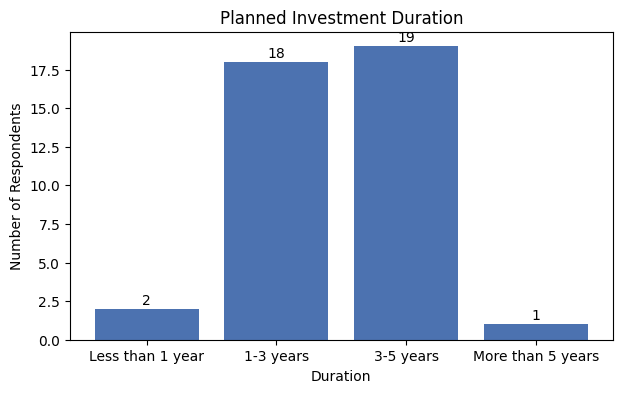

In [5]:
plt.figure(figsize=(7, 4))
bars = plt.bar(counts.index, counts.values, color="#4C72B0")

for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
             int(bar.get_height()), ha="center")

plt.title("Planned Investment Duration")
plt.xlabel("Duration")
plt.ylabel("Number of Respondents")
plt.savefig("../outputs/charts/task08_investment_duration.png", dpi=150, bbox_inches="tight")
plt.show()

## Finding

Duration was recorded as ranges, so I converted each range to a midpoint: less than 1 year = 0.5, 1-3 years = 2, 3-5 years = 4, and more than 5 years = 6. The last value is a judgement call because that range has no upper limit.

With this mapping, the average planned duration is 2.98 years and the median is 3 years. Most respondents (37 of 40, 92.5%) plan to invest for 1 to 5 years. Only 2 plan less than a year and 1 plans more than 5 years.

The average is not sensitive to the open-ended range: taking "more than 5 years" as 8 instead of 6 only moves the average to 3.02 years.